In [58]:
#!/usr/bin/env python3
"""
Fetch vertical seismometer channels near an event and estimate P/S arrivals.

Requirements:
    pip install obspy

What it does:
1) Queries FDSN station metadata for all vertical channels (*Z) within 50 km
   of the event epicenter at the event time.
2) Downloads waveform snippets for those channels around origin time.
3) Estimates P and S arrival times using constant velocities and
   straight-line travel time: t = distance_km / velocity_km_s.
4) Prints a simple table and writes outputs:
   - vertical_channels_waveforms.mseed
   - station_arrival_predictions.csv
"""

from __future__ import annotations

import csv
from dataclasses import dataclass
from typing import List

from obspy import Stream, UTCDateTime
from obspy.clients.fdsn import Client
from obspy.clients.fdsn.header import FDSNException, FDSNNoDataException
from obspy.geodetics import gps2dist_azimuth, kilometers2degrees


# -----------------------------
# Event and model assumptions
# -----------------------------
EVENT_TIME = UTCDateTime("2023-07-28T19:11:22")
EVENT_LAT = 59.004
EVENT_LON = -153.977
SEARCH_RADIUS_KM = 200.0

# Very simple constant velocity model (km/s)
VP_KM_S = 6.0
VS_KM_S = 3.5

# Waveform window to download around origin time
PRE_EVENT_S = 60
POST_EVENT_S = 300

# FDSN data center (EarthScope/IRIS works for many regional stations)
FDSN_PROVIDER = "IRIS"


@dataclass
class ChannelArrival:
    network: str
    station: str
    location: str
    channel: str
    station_lat: float
    station_lon: float
    distance_km: float
    p_arrival: UTCDateTime
    s_arrival: UTCDateTime


def main() -> None:
    client = Client(FDSN_PROVIDER)

    maxradius_deg = kilometers2degrees(SEARCH_RADIUS_KM)
    inventory = client.get_stations(
        latitude=EVENT_LAT,
        longitude=EVENT_LON,
        maxradius=maxradius_deg,
        level="channel",
        channel="*HZ,*NZ",
        startbefore=EVENT_TIME,
        endafter=EVENT_TIME,
    )

    print(inventory)

    arrivals: List[ChannelArrival] = []
    waveforms = Stream()

    t1 = EVENT_TIME - PRE_EVENT_S
    t2 = EVENT_TIME + POST_EVENT_S

    for net in inventory:
        for sta in net:
            for cha in sta:
                if not cha.code.endswith("Z"):
                    continue

                dist_m, _, _ = gps2dist_azimuth(
                    EVENT_LAT,
                    EVENT_LON,
                    cha.latitude,
                    cha.longitude,
                )
                dist_km = dist_m / 1000.0
                if dist_km > SEARCH_RADIUS_KM:
                    continue

                p_arrival = EVENT_TIME + dist_km / VP_KM_S
                s_arrival = EVENT_TIME + dist_km / VS_KM_S

                arrivals.append(
                    ChannelArrival(
                        network=net.code,
                        station=sta.code,
                        location=cha.location_code,
                        channel=cha.code,
                        station_lat=cha.latitude,
                        station_lon=cha.longitude,
                        distance_km=dist_km,
                        p_arrival=p_arrival,
                        s_arrival=s_arrival,
                    )
                )

                try:
                    st = client.get_waveforms(
                        net.code,
                        sta.code,
                        cha.location_code,
                        cha.code,
                        t1,
                        t2,
                        attach_response=True
                    )
                    waveforms += st
                except FDSNNoDataException:
                    # Channel exists in metadata but no waveform data in this window.
                    continue
                except FDSNException as err:
                    # Surface provider/transport-related issues per channel.
                    print(
                        f"Waveform request failed for "
                        f"{net.code}.{sta.code}.{cha.location_code}.{cha.code}: {err}"
                    )

    arrivals.sort(key=lambda x: x.distance_km)

    print("\nVertical channels within 50 km and predicted arrivals")
    print("=" * 92)
    print(
        f"{'NET.STA.LOC.CHA':24s} {'Dist(km)':>9s} "
        f"{'P-arrival (UTC)':25s} {'S-arrival (UTC)':25s}"
    )
    print("-" * 92)

    for a in arrivals:
        nslc = f"{a.network}.{a.station}.{a.location}.{a.channel}"
        print(
            f"{nslc:24s} {a.distance_km:9.2f} "
            f"{str(a.p_arrival):25s} {str(a.s_arrival):25s}"
        )

    if len(waveforms) > 0:
        waveforms.merge(fill_value="interpolate")
        waveforms.write("vertical_channels_waveforms.mseed", format="MSEED")
        print("\nSaved waveform snippets to: vertical_channels_waveforms.mseed")
    else:
        print("\nNo waveform snippets were downloaded for the selected window.")

    with open("station_arrival_predictions.csv", "w", newline="", encoding="utf-8") as f:
        writer = csv.writer(f)
        writer.writerow(
            [
                "network",
                "station",
                "location",
                "channel",
                "station_lat",
                "station_lon",
                "distance_km",
                "p_arrival_utc",
                "s_arrival_utc",
            ]
        )
        for a in arrivals:
            writer.writerow(
                [
                    a.network,
                    a.station,
                    a.location,
                    a.channel,
                    f"{a.station_lat:.6f}",
                    f"{a.station_lon:.6f}",
                    f"{a.distance_km:.3f}",
                    str(a.p_arrival),
                    str(a.s_arrival),
                ]
            )

    print("Saved arrival table to: station_arrival_predictions.csv")


if __name__ == "__main__":
    main()


/Users/zoekrauss/miniconda3/envs/seiscloud/lib/python3.8/site-packages/obspy/clients/fdsn/client.py:251: ObsPyDeprecationWarning: IRIS is now EarthScope, please consider changing the FDSN client short URL to 'EARTHSCOPE'.
  warnings.warn(msg, ObsPyDeprecationWarning)


Inventory created at 2026-10-01T15:38:41.168900Z
	Created by: EarthScope WEB SERVICE: fdsnws-station | version: 1.1.58
		    https://service.earthscope.org/fdsnws/station/1/query?channel=%2AHZ...
	Sending institution: EarthScope (EarthScope)
	Contains:
		Networks (5):
			AK, AV, II, NP, PN
		Stations (69):
			AK.BRLK (Bradley Lake, AK, USA)
			AK.CNP (China Poot, AK, USA)
			AK.DAM1 (Bradley Dam 1, AK, USA)
			AK.DAM2 (Bradley Dam 2, AK, USA)
			AK.HOM (Homer Trailer, AK, USA)
			AK.O18K (Koktuh Hills, AK, USA)
			AK.O19K (Port Alsworth, AK, USA)
			AK.O20K (Slope Mountain, AK, USA)
			AK.P17K (Kvichak River, AK, USA)
			AK.Q19K (Cape Douglas, AK, USA)
			AK.R18K (Karluk, AK, USA)
			AV.ACH (Angle Creek Headwaters, Katmai, Alaska)
			AV.ANCK (Angle Creek, Katmai Volcanic Cluster, Alaska)
			AV.AU22 (Augustine Mound, Augustine Volcano, Alaska)
			AV.AUCH (Augustine Cone H, Augustine Volcano, Alaska)
			AV.AUJA (Augustine Junction, Augustine Volcano, Alaska)
			AV.AUJK (Augustine Juergen

/var/folders/xw/1gvhr_pd4s13dn10v1k1kzx80000gn/T/ipykernel_10865/1396576800.py:120: ObsPyDeprecationWarning: attach_response is deprecated and will be removed in a future release. Use remove_response() instead.
  st = client.get_waveforms(
/var/folders/xw/1gvhr_pd4s13dn10v1k1kzx80000gn/T/ipykernel_10865/1396576800.py:120: ObsPyDeprecationWarning: attach_response is deprecated and will be removed in a future release. Use remove_response() instead.
  st = client.get_waveforms(
/var/folders/xw/1gvhr_pd4s13dn10v1k1kzx80000gn/T/ipykernel_10865/1396576800.py:120: ObsPyDeprecationWarning: attach_response is deprecated and will be removed in a future release. Use remove_response() instead.
  st = client.get_waveforms(
/var/folders/xw/1gvhr_pd4s13dn10v1k1kzx80000gn/T/ipykernel_10865/1396576800.py:120: ObsPyDeprecationWarning: attach_response is deprecated and will be removed in a future release. Use remove_response() instead.
  st = client.get_waveforms(
/var/folders/xw/1gvhr_pd4s13dn10v1k1kzx8

In [ ]:
client = Client(FDSN_PROVIDER)

maxradius_deg = kilometers2degrees(SEARCH_RADIUS_KM)
inventory = client.get_stations(
    latitude=EVENT_LAT,
    longitude=EVENT_LON,
    maxradius=maxradius_deg,
    level="response",
    channel="*HZ,*NZ",
    startbefore=EVENT_TIME,
    endafter=EVENT_TIME,
)


## Start plotting here

In [59]:
import cartopy.crs as ccrs         # to plot maps with different projections
import cartopy.feature as cfeature # to plot coastlines, land, borders, etc.


In [60]:
import obspy

In [61]:
test = obspy.read('vertical_channels_waveforms.mseed')

In [62]:
test

75 Trace(s) in Stream:

AK.BRLK..BHZ | 2023-07-28T19:10:22.008393Z - 2023-07-28T19:16:21.988393Z | 50.0 Hz, 18000 samples
...
(73 other traces)
...
NP.NIKO.01.HNZ | 2023-07-28T19:10:22.000000Z - 2023-07-28T19:16:22.000000Z | 200.0 Hz, 72001 samples

[Use "print(Stream.__str__(extended=True))" to print all Traces]

In [63]:
import pandas as pd
import matplotlib.pyplot as plt
test = pd.read_csv('station_arrival_predictions.csv')

In [64]:
terra_loc = pd.read_csv('TERRA_coords.xycz',sep='\t',names=['lon','lat','chan','elev'])
kkfls_loc = pd.read_csv('KKFLS_coords.xycz',sep='\t',names=['lon','lat','chan','elev'])

In [65]:
kkfls_loc

,lon,lat,chan,elev
0,NaN,NaN,0,NaN
1,NaN,NaN,1,NaN
2,NaN,NaN,2,NaN
3,NaN,NaN,3,NaN
4,NaN,NaN,4,NaN
...,...,...,...,...
8526,-151.956522,59.070130,8526,-199.829887
8527,-151.956427,59.070059,8527,-199.807120
8528,-151.956333,59.069989,8528,-199.782754
8529,-151.956238,59.069918,8529,-199.757143


In [66]:
import matplotlib
matplotlib.rcParams['font.family'] = ['Arial']
plt.rcParams.update({'font.size': 18}) 

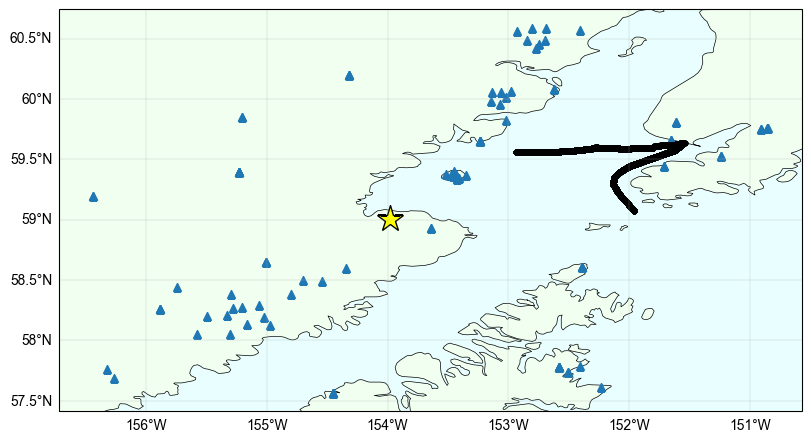

In [67]:
fig = plt.figure(figsize=[8,8],constrained_layout=True)
ax=fig.add_subplot(projection=ccrs.PlateCarree(central_longitude=0))
ax.coastlines(linewidth=0.5)
ax.add_feature(cfeature.LAND, facecolor='honeydew') 
ax.add_feature(cfeature.OCEAN, facecolor='lightcyan',alpha=0.7)

ax.plot(test.station_lon,test.station_lat,'^')
ax.plot(EVENT_LON,EVENT_LAT,'*',markersize=20,markerfacecolor='yellow',markeredgecolor='k')
ax.plot(kkfls_loc.lon,kkfls_loc.lat,'k.')
ax.plot(terra_loc.lon,terra_loc.lat,'k.')

# ax.set_xlim(-155,-148)
# ax.set_ylim(57,62)

gl = ax.gridlines(draw_labels=True,linewidth=0.2) 
gl.xlabel_style = {'size':10}
gl.ylabel_style = {'size':10}
gl.top_labels = False
gl.right_labels = False

In [68]:
stream = obspy.read('vertical_channels_waveforms.mseed')

In [69]:
picks = pd.read_csv('station_arrival_predictions.csv')

In [70]:
picks

,network,station,location,channel,station_lat,station_lon,distance_km,p_arrival_utc,s_arrival_utc
0,AK,Q19K,NaN,BHZ,58.92870,-153.64460,20.882,2023-07-28T19:11:25.480353Z,2023-07-28T19:11:27.966320Z
1,AK,Q19K,NaN,LHZ,58.92870,-153.64460,20.882,2023-07-28T19:11:25.480353Z,2023-07-28T19:11:27.966320Z
2,AV,AUSB,NaN,BHZ,59.33300,-153.42840,48.246,2023-07-28T19:11:30.041022Z,2023-07-28T19:11:35.784609Z
3,AV,AUJA,NaN,BHZ,59.33956,-153.42258,49.016,2023-07-28T19:11:30.169379Z,2023-07-28T19:11:36.004650Z
4,AV,AULG,NaN,BHZ,59.37730,-153.51930,49.129,2023-07-28T19:11:30.188204Z,2023-07-28T19:11:36.036921Z
...,...,...,...,...,...,...,...,...,...
108,AV,PLK2,NaN,BHZ,57.76340,-156.32640,194.872,2023-07-28T19:11:54.478723Z,2023-07-28T19:12:17.677811Z
109,AV,RDT,NaN,BHZ,60.57260,-152.40790,195.700,2023-07-28T19:11:54.616693Z,2023-07-28T19:12:17.914332Z
110,AK,DAM2,NaN,HNZ,59.75530,-150.85550,196.154,2023-07-28T19:11:54.692350Z,2023-07-28T19:12:18.044029Z
111,AK,DAM1,NaN,HNZ,59.75540,-150.85130,196.374,2023-07-28T19:11:54.729079Z,2023-07-28T19:12:18.106992Z


## Get amplitude of P picks

In [71]:
import numpy as np

In [72]:
stream = obspy.read('vertical_channels_waveforms.mseed')

client = Client(FDSN_PROVIDER)

maxradius_deg = kilometers2degrees(SEARCH_RADIUS_KM)
inventory = client.get_stations(
    latitude=EVENT_LAT,
    longitude=EVENT_LON,
    maxradius=maxradius_deg,
    level="response",
    channel="*HZ,*NZ",
    startbefore=EVENT_TIME,
    endafter=EVENT_TIME,
)

/Users/zoekrauss/miniconda3/envs/seiscloud/lib/python3.8/site-packages/obspy/clients/fdsn/client.py:251: ObsPyDeprecationWarning: IRIS is now EarthScope, please consider changing the FDSN client short URL to 'EARTHSCOPE'.
  warnings.warn(msg, ObsPyDeprecationWarning)


In [73]:
p_amps = []
all_amps = []
p_dist = []
p_ds_amps = []
all_ds_amps = []
for i in range(len(stream)):

    station = stream[i].stats.station
    check_ind = [j for j,s in enumerate(picks.station.to_list()) if s==station][0]
    p_arrival_utc = picks.iloc[check_ind].p_arrival_utc

    p_sec = obspy.UTCDateTime(p_arrival_utc) - stream[i].stats.starttime 

    
    tr = stream[i].remove_response(inventory=inventory,output="VEL")

    if tr.stats.sampling_rate >= 50:
        print(tr.stats.sampling_rate)

        p_dist.append(picks.iloc[i].distance_km)

        
        p_window_ind = [j for j,t in enumerate(tr.times()) if (t>p_sec - 3) & (t<p_sec+2)]
        p_data = [tr.data[j] for j in p_window_ind]
        p_amp = np.max(np.abs(p_data))
        p_amps.append(p_amp)
        all_amps.append(np.max(np.abs(tr.data)))

        # Now downsample
        tr2 = tr.copy()
        t1 = tr2.stats.starttime
        t2 = tr2.stats.endtime
        tr2.trim(t1-100,t2,fill_value=np.int32(np.mean(tr2.data[0:10])),pad=True) # pad ends so we can cut off edge effects
        tr2.trim(t1-100,t2+100,fill_value=np.int32(np.mean(tr2.data[-10:])),pad=True)

        # If sampling rate is too large, need to do smaller steps:
        if tr2.stats.sampling_rate/8 > 16:
            tr2.resample(40.0, no_filter=False) # do a smaller resampling step first
        
        tr2.resample(8.0,no_filter=False)
        tr2.trim(t1,t2) # cut off edge effects

        p_window_ind = [j for j,t in enumerate(tr2.times()) if (t>p_sec - 3) & (t<p_sec+2)]
        p_data = [tr2.data[j] for j in p_window_ind]
        p_amp = np.max(np.abs(p_data))
        p_ds_amps.append(p_amp)
        all_ds_amps.append(np.max(np.abs(tr2.data)))
        

50.0
100.0
50.0
50.0
200.0
200.0
50.0
200.0
50.0
50.0
100.0
50.0
50.0
50.0
50.0
50.0
50.0
50.0
50.0
50.0
50.0
50.0
50.0
50.0
50.0
50.0
50.0
50.0
50.0
50.0
50.0
50.0
50.0
50.0
50.0
50.0
50.0
50.0
50.0
50.0
50.0
50.0
50.0
50.0
50.0
50.0
50.0
50.0
50.0
50.0
50.0
50.0
50.0
50.0
200.0
200.0


In [74]:
all_amp_ratio = np.array(all_ds_amps)/np.array(all_amps)
p_amp_ratio = np.array(p_ds_amps)/np.array(p_amps)

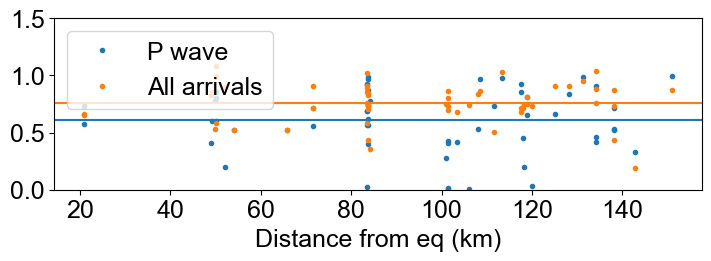

In [75]:
fig,ax = plt.subplots(1,figsize=[7,2.5],constrained_layout = True)
ax.plot(p_dist,p_amp_ratio,'.',color='tab:blue',label='P wave')
ax.plot(p_dist,all_amp_ratio,'.',color='tab:orange',label='All arrivals')

ax.axhline(np.median(p_amp_ratio),color='tab:blue')
ax.axhline(np.median(all_amp_ratio),color='tab:orange')

ax.set_xlabel('Distance from eq (km)')
ax.set_ylim(0,1.5)
ax.legend()

In [76]:
matplotlib.rcParams['font.family'] = ['Arial']
plt.rcParams.update({'font.size': 14}) 

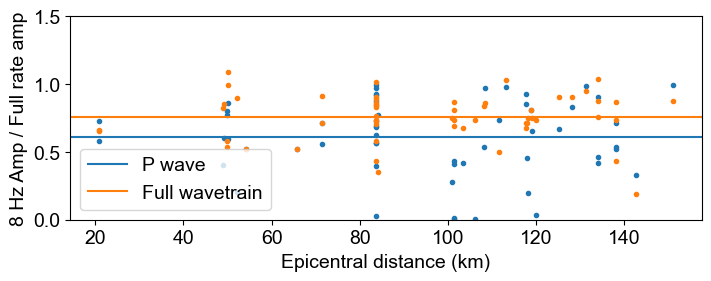

In [78]:
fig,ax = plt.subplots(1,figsize=[7,2.7],constrained_layout = True)
ax.plot(p_dist,p_amp_ratio,'.')
ax.plot(p_dist,all_amp_ratio,'.')

ax.axhline(np.median(p_amp_ratio),color='tab:blue',label='P wave')
ax.axhline(np.median(all_amp_ratio),color='tab:orange',label='Full wavetrain')

ax.legend(loc='lower left')

ax.set_ylim(0,1.5)
ax.set_xlabel('Epicentral distance (km)')
ax.set_ylabel('8 Hz Amp / Full rate amp')

fig.patch.set_facecolor('none')  # Makes the outer figure background transparent
ax.patch.set_facecolor('white')  # Keeps the inner axes background solid white


plt.savefig('/Users/zoekrauss/shakealert_8hz/kona_figs/alaska_seismic_amplitude_scatter.png', dpi=300)

In [55]:
np.median(p_amp_ratio)

0.6132308862467892

In [56]:
np.median(all_amp_ratio)

0.7557096050258328

In [25]:
%matplotlib widget

for i in range(10):

    station = test[i].stats.station
    check_ind = [j for j,s in enumerate(picks.station.to_list()) if s==station][0]
    p_arrival_utc = picks.iloc[check_ind].p_arrival_utc

    p_sec = obspy.UTCDateTime(p_arrival_utc) - test[i].stats.starttime 
    
    fig,ax = plt.subplots(1)
    ax.plot(test[i].times(),test[i].data)

    ax.set_title(test[i].stats.station)
    ax.axvline(p_sec,color='k')

    ax.set_xlim(p_sec-10,p_sec+10)

KeyError: 0